# Ước lượng tổng các chữ số MNIST bằng CNN + LSTM — bản PyTorch

Chuyển từ notebook Keras gốc: `Example/examples/3. CNN + LSTM/MNIST_CNN_LSTM.ipynb`.
Giữ nguyên dữ liệu, kiến trúc, hàm mất mát, optimizer, learning rate, batch size; chỉ thay framework.

**Đối chiếu Keras → PyTorch trong notebook này**

| Keras (gốc) | PyTorch (bản chuyển) |
|---|---|
| input `(N, 8, 28, 28, 1)` | input `(N, 8, 1, 28, 28)` (chuỗi 8 ảnh, channels-first) |
| `TimeDistributed(Conv2D/MaxPooling2D/Dropout/Flatten)` | gộp trục thời gian vào batch: `x.view(B*T, C, H, W)` → CNN → `view(B, T, -1)` |
| `LSTM(128, return_sequences=True)` → `LSTM(128, return_sequences=False)` | `nn.LSTM(2304, 128, batch_first=True)` → `nn.LSTM(128, 128, batch_first=True)` lấy `out[:, -1]` (bước cuối) |
| `Dropout(0.22)` → `Dense(1)` | `nn.Dropout(0.22)` → `nn.Linear(128, 1)` |
| `loss='mean_absolute_error'`, `SGD(lr=0.01)` | `nn.L1Loss()`, `torch.optim.SGD(lr=0.01)` |

> **Cấu hình chạy trên CPU:** bản gốc dùng 60 000 chuỗi train / 10 000 chuỗi test, 30 epoch (thầy ghi ~13,5 giờ trên
> Core i7; ~17 phút/epoch trên CPU của máy chạy bài này). Notebook giữ **nguyên cách sinh dữ liệu và kiến trúc**, nhưng
> mặc định dùng `N_TRAIN = 10000`, `N_TEST = 2000`, `EPOCHS = 10`. Có GPU thì đặt lại 60000 / 10000 / 30.
>
> **Khác biệt nhỏ về số tham số:** `nn.LSTM` của PyTorch có 2 vector bias (`b_ih`, `b_hh`) cho mỗi cổng, Keras chỉ có 1,
> nên mỗi lớp LSTM nhiều hơn 4 × 128 = 512 tham số (tổng +1 024). Về khả năng biểu diễn hai cách là tương đương.

# Import libraries

In [1]:
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

# Thư mục gốc bài nộp = thư mục cha gần nhất có chứa "data/"
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
DATA = ROOT / "data"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("ROOT =", ROOT, "| device =", DEVICE, "| torch", torch.__version__)

N_TRAIN, N_TEST, EPOCHS = 10000, 2000, 10   # Keras gốc: 60000, 10000, 30
torch.manual_seed(2024)

ROOT = d:\SGU\deep-learning\Tuan13\BTL03_TranQuocAn_3123411009 | device = cpu | torch 2.14.0+cpu


In [2]:
def summary(model, input_size, keras_params=None):
    """Tương đương model.summary() của Keras: tên lớp, output shape, số tham số."""
    rows, hooks = [], []
    for name, m in model.named_modules():
        if len(list(m.children())) == 0 and name:
            hooks.append(m.register_forward_hook(
                lambda mod, i, o, name=name: rows.append(
                    (name, type(mod).__name__, tuple(o.shape) if torch.is_tensor(o) else "-",
                     sum(p.numel() for p in mod.parameters(recurse=False))))))
    was_training = model.training
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, *input_size, device=next(model.parameters()).device))
    model.train(was_training)
    for h in hooks:
        h.remove()
    print(f"{'Layer':<22}{'Type':<16}{'Output shape':<26}{'Param #':>12}")
    print("=" * 76)
    for n, t, s, p in rows:
        print(f"{n:<22}{t:<16}{str(s):<26}{p:>12,}")
    total = sum(p.numel() for p in model.parameters())
    print("=" * 76)
    print(f"Total params: {total:,}" + (f"   (Keras gốc: {keras_params:,})" if keras_params else ""))

def run_epoch(model, loader, loss_fn, metric_fn=None, optimizer=None, augment=None):
    """1 epoch train (có optimizer) hoặc đánh giá (optimizer=None). Trả về (loss, metric) trung bình theo mẫu."""
    training = optimizer is not None
    model.train(training)
    tot_loss, tot_metric, n = 0.0, 0.0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            if augment is not None and training:
                xb = augment(xb)
            out = model(xb)                      # forward
            loss = loss_fn(out, yb)              # loss
            if training:
                optimizer.zero_grad()            # xoá gradient cũ
                loss.backward()                  # backpropagation
                optimizer.step()                 # cập nhật trọng số
            tot_loss += loss.item() * len(xb)
            if metric_fn is not None:
                tot_metric += metric_fn(out.detach(), yb) * len(xb)
            n += len(xb)
    return tot_loss / n, (tot_metric / n if metric_fn is not None else None)


def fit(model, train_loader, val_loader, epochs, optimizer, loss_fn, metric_fn=None, metric_name="accuracy",
        augment=None):
    """Tương đương model.fit(..., validation_data=...): in log mỗi epoch, trả về history."""
    history = {"loss": [], "val_loss": [], metric_name: [], "val_" + metric_name: []}
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_m = run_epoch(model, train_loader, loss_fn, metric_fn, optimizer, augment)
        va_loss, va_m = run_epoch(model, val_loader, loss_fn, metric_fn)
        history["loss"].append(tr_loss); history["val_loss"].append(va_loss)
        history[metric_name].append(tr_m); history["val_" + metric_name].append(va_m)
        msg = f"Epoch {ep}/{epochs} - {time.time() - t0:.0f}s - loss: {tr_loss:.4f}"
        if metric_fn is not None:
            msg += f" - {metric_name}: {tr_m:.4f}"
        msg += f" - val_loss: {va_loss:.4f}"
        if metric_fn is not None:
            msg += f" - val_{metric_name}: {va_m:.4f}"
        print(msg, flush=True)
    return history


def accuracy(out, y):
    """Độ chính xác phân loại: so argmax của logits với nhãn số nguyên."""
    return (out.argmax(1) == y).float().mean().item()


def plot_history(history, metric_name="accuracy"):
    keys = [("loss", "val_loss")] + ([(metric_name, "val_" + metric_name)] if history[metric_name][0] is not None else [])
    fig, axes = plt.subplots(1, len(keys), figsize=(6 * len(keys), 3.8))
    axes = np.atleast_1d(axes)
    for ax, (a, b) in zip(axes, keys):
        ax.plot(range(1, len(history[a]) + 1), history[a], marker="o", label="train")
        ax.plot(range(1, len(history[b]) + 1), history[b], marker="o", label="validation")
        ax.set_xlabel("epoch"); ax.set_ylabel(a); ax.grid(alpha=.3); ax.legend()
    plt.tight_layout(); plt.show()

def load_mnist():
    """Tương đương keras.datasets.mnist.load_data(): tải đúng file mnist.npz mà Keras dùng."""
    path = DATA / "mnist.npz"
    if not path.exists():
        import urllib.request
        path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve("https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz", path)
    d = np.load(path)
    return (d["x_train"], d["y_train"]), (d["x_test"], d["y_test"])

# (1) Data

In [3]:
(X_train_raw, y_train_temp), (X_test_raw, y_test_temp) = load_mnist()
X_train_raw = X_train_raw.astype("float32") / 255
X_test_raw = X_test_raw.astype("float32") / 255
print("X_train_raw shape:", X_train_raw.shape)

X_train_raw shape: (60000, 28, 28)


## Tạo dữ liệu mới (giữ nguyên thuật toán bản gốc)
- Mỗi mẫu là chuỗi `maxToAdd = 8` ảnh; lấy ngẫu nhiên 1–8 ảnh MNIST, phần còn lại là ảnh đen.
- Nhãn = tổng các chữ số trong chuỗi.

In [4]:
np.random.seed(2018)          # giống bản gốc
maxToAdd, size = 8, 28


def make_sequences(X_raw, y_raw, n):
    x = np.zeros((n, maxToAdd, 1, size, size), dtype=np.float32)   # float32 (bản gốc float64 tốn gấp đôi RAM)
    y = np.zeros(n, dtype=np.float32)
    for i in range(n):
        numToAdd = int(np.ceil(np.random.rand() * maxToAdd))       # số ảnh trong chuỗi
        indices = np.random.choice(X_raw.shape[0], size=numToAdd)
        x[i, :numToAdd, 0] = X_raw[indices]
        y[i] = np.sum(y_raw[indices])
    return x, y


x_train, y_train = make_sequences(X_train_raw, y_train_temp, N_TRAIN)
x_test, y_test = make_sequences(X_test_raw, y_test_temp, N_TEST)
print("x_train shape:", x_train.shape, "| y_train shape:", y_train.shape)
print("x_test shape: ", x_test.shape, "| y_test shape: ", y_test.shape)

train_loader = DataLoader(TensorDataset(torch.from_numpy(x_train), torch.from_numpy(y_train).unsqueeze(1)), batch_size=128, shuffle=True)
test_loader = DataLoader(TensorDataset(torch.from_numpy(x_test), torch.from_numpy(y_test).unsqueeze(1)), batch_size=256)

x_train shape: (10000, 8, 1, 28, 28) | y_train shape: (10000,)
x_test shape:  (2000, 8, 1, 28, 28) | y_test shape:  (2000,)


# (2) Declare model

In [5]:
class CnnLstm(nn.Module):
    def __init__(self):
        super().__init__()
        # phần CNN dùng chung cho mọi bước thời gian (= TimeDistributed)
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Dropout(0.2),     # conv1, pool1
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Dropout(0.2),   # conv2, pool2
            nn.Conv2d(128, 256, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Dropout(0.2),  # conv3, pool3
            nn.Flatten())                                                                     # 256*3*3 = 2304
        self.lstm1 = nn.LSTM(input_size=2304, hidden_size=128, batch_first=True)   # return_sequences=True
        self.lstm2 = nn.LSTM(input_size=128, hidden_size=128, batch_first=True)    # return_sequences=False
        self.lstm_dropout = nn.Dropout(0.22)
        self.out = nn.Linear(128, 1)

    def forward(self, x):                      # x: (B, T, 1, 28, 28)
        B, T = x.shape[:2]
        f = self.cnn(x.reshape(B * T, *x.shape[2:])).reshape(B, T, -1)   # TimeDistributed(CNN)
        h, _ = self.lstm1(f)                   # (B, T, 128)
        h, _ = self.lstm2(h)                   # (B, T, 128)
        return self.out(self.lstm_dropout(h[:, -1]))   # chỉ lấy bước cuối = return_sequences=False


def keras_init_lstm(model):
    """Giống mặc định Keras: kernel glorot_uniform, recurrent orthogonal, bias 0 (cổng quên = 1)."""
    for m in model.modules():
        if isinstance(m, (nn.Linear, nn.Conv2d)):
            nn.init.xavier_uniform_(m.weight); nn.init.zeros_(m.bias)
        elif isinstance(m, nn.LSTM):
            H = m.hidden_size
            for name, p in m.named_parameters():
                if "weight_ih" in name:
                    for g in range(4): nn.init.xavier_uniform_(p.data[g * H:(g + 1) * H])
                elif "weight_hh" in name:
                    for g in range(4): nn.init.orthogonal_(p.data[g * H:(g + 1) * H])
                elif "bias_ih" in name:
                    p.data.zero_(); p.data[H:2 * H] = 1.0       # unit_forget_bias=True (thứ tự cổng PyTorch: i, f, g, o)
                elif "bias_hh" in name:
                    p.data.zero_()
    return model


model = keras_init_lstm(CnnLstm()).to(DEVICE)
summary(model, (maxToAdd, 1, 28, 28), keras_params=1_747_073)

Layer                 Type            Output shape                   Param #
cnn.0                 Conv2d          (8, 64, 28, 28)                    640
cnn.1                 ReLU            (8, 64, 28, 28)                      0
cnn.2                 MaxPool2d       (8, 64, 14, 14)                      0
cnn.3                 Dropout         (8, 64, 14, 14)                      0
cnn.4                 Conv2d          (8, 128, 14, 14)                73,856
cnn.5                 ReLU            (8, 128, 14, 14)                     0
cnn.6                 MaxPool2d       (8, 128, 7, 7)                       0
cnn.7                 Dropout         (8, 128, 7, 7)                       0
cnn.8                 Conv2d          (8, 256, 7, 7)                 295,168
cnn.9                 ReLU            (8, 256, 7, 7)                       0
cnn.10                MaxPool2d       (8, 256, 3, 3)                       0
cnn.11                Dropout         (8, 256, 3, 3)                       0

# (3) Train defined model

Epoch 1/10 - 154s - loss: 13.1499 - val_loss: 9.2865


Epoch 2/10 - 136s - loss: 6.0511 - val_loss: 7.1549


Epoch 3/10 - 141s - loss: 4.8823 - val_loss: 4.5474


Epoch 4/10 - 144s - loss: 4.6745 - val_loss: 4.2305


Epoch 5/10 - 142s - loss: 4.5522 - val_loss: 4.2602


Epoch 6/10 - 132s - loss: 4.3041 - val_loss: 3.8676


Epoch 7/10 - 134s - loss: 4.1102 - val_loss: 6.0238


Epoch 8/10 - 130s - loss: 3.9519 - val_loss: 5.4308


Epoch 9/10 - 146s - loss: 3.7504 - val_loss: 4.0720


Epoch 10/10 - 142s - loss: 3.6159 - val_loss: 3.0204


> training time is 23.3421 minutes


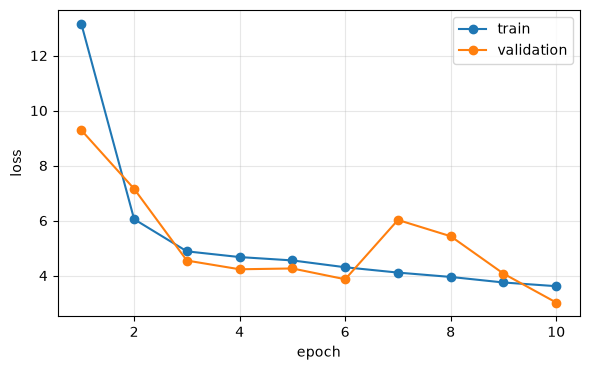

In [6]:
loss_fn = nn.L1Loss()                                   # 'mean_absolute_error'
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
starting_time = time.time()
history = fit(model, train_loader, test_loader, EPOCHS, optimizer, loss_fn)
print("> training time is %.4f minutes" % ((time.time() - starting_time) / 60))
plot_history(history)

# (4) Evaluate trained model

In [7]:
test_mae, _ = run_epoch(model, test_loader, loss_fn)
print("Mean absolute error of testing set:", test_mae)

Mean absolute error of testing set: 3.0204439659118654


> actual summation = 32
> estimated summation = 34.004


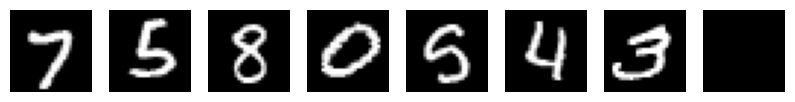

In [8]:
model.eval()
k = np.random.choice(x_test.shape[0], size=1)[0]
plt.figure(figsize=(10, 2.2))
for t in range(maxToAdd):
    plt.subplot(1, maxToAdd, t + 1); plt.axis("off"); plt.imshow(x_test[k, t, 0], cmap="gray")
with torch.no_grad():
    est_sum = model(torch.from_numpy(x_test[k:k + 1]).to(DEVICE)).item()
print("> actual summation = %d" % y_test[k])
print("> estimated summation = %.3f" % est_sum)
plt.show()